In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["font.sans-serif"] = ["SimHei"]   
plt.rcParams["axes.unicode_minus"] = False     
# 读取数据
df = pd.read_csv('data/city_economy.csv')
df.head()

,city,province,type,gdp,population,salary,month
0,深圳,广东,一线城市,3200,1756,18500,1月
1,深圳,广东,一线城市,3350,1756,19200,2月
2,深圳,广东,一线城市,3180,1756,18800,3月
3,深圳,广东,一线城市,3420,1756,19500,4月
4,广州,广东,一线城市,2800,1868,15200,1月


In [2]:
# 数据概览
print('数据形状:', df.shape)
print('\n数据类型:')
print(df.dtypes)
print('\n描述性统计:')
print(df.describe())

数据形状: (32, 7)

数据类型:
city          object
province      object
type          object
gdp            int64
population     int64
salary         int64
month         object
dtype: object

描述性统计:
               gdp   population        salary
count    32.000000    32.000000     32.000000
mean   2109.062500  1332.500000  14403.125000
std     695.118274   562.985819   2358.305074
min    1150.000000   244.000000  11500.000000
25%    1525.000000  1041.250000  12650.000000
50%    2025.000000  1301.000000  13900.000000
75%    2637.500000  1784.000000  15675.000000
max    3420.000000  2119.000000  19500.000000


In [3]:

# 查空
print(df.isnull().sum())
# 查重
print(df.duplicated().sum())
# 检查异常值（IQR法）
def detect_outliers(df, col):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3-q1
    lower = q1-1.5*iqr
    upper = q3+1.5*iqr
    outliers = df[(df[col]<lower)|(df[col]>upper)]
    print(f"离散点:{col}, {len(outliers)}个 ,范围[{lower:.2f},{upper:.2f}]")
    return outliers
outliers = detect_outliers(df,"salary")
outliers_gdp = detect_outliers(df,"gdp")
# 类型转换
df["gdp"] = df["gdp"].astype(float)
df["salary"] = df["salary"].astype(float)
df["type"] = df["type"].astype("category")
df["month"] = pd.to_datetime(df["month"],format="%m月")
# 特征工程
df = df.assign(gdp_level = np.where(df["gdp"]>=2800,"高",np.where(df["gdp"]>=1800,"中","低")),
              salary_z = (df["salary"]-df["salary"].mean())/df["salary"].std())
print(df)

city          0
province      0
type          0
gdp           0
population    0
salary        0
month         0
dtype: int64
0
离散点:salary, 0个 ,范围[8112.50,20212.50]
离散点:gdp, 0个 ,范围[-143.75,4306.25]
   city province   type     gdp  population   salary      month gdp_level  \
0    深圳       广东   一线城市  3200.0        1756  18500.0 1900-01-01         高   
1    深圳       广东   一线城市  3350.0        1756  19200.0 1900-02-01         高   
2    深圳       广东   一线城市  3180.0        1756  18800.0 1900-03-01         高   
3    深圳       广东   一线城市  3420.0        1756  19500.0 1900-04-01         高   
4    广州       广东   一线城市  2800.0        1868  15200.0 1900-01-01         高   
5    广州       广东   一线城市  2750.0        1868  14800.0 1900-02-01         中   
6    广州       广东   一线城市  2900.0        1868  15500.0 1900-03-01         高   
7    广州       广东   一线城市  2850.0        1868  15000.0 1900-04-01         高   
8    珠海       广东   二线城市  1200.0         244  12000.0 1900-01-01         低   
9    珠海       广东   二线城市  1150.0  

In [11]:
# 分组分析
province_stats = df.groupby("province").agg(gdp_mean=("gdp","mean"),
                                            salary_mean=("salary","mean"),
                                            city_count=("city","count")).sort_values("gdp_mean",ascending=False)
print(province_stats)
# 相关性矩阵
corr = df[["salary","gdp","population"]].corr()
print(corr)
# 透视表
pt = pd.pivot_table(df,values="salary",index="province",columns="gdp_level",aggfunc="mean",fill_value=0)
print(pt)

          gdp_mean  salary_mean  city_count
province                                   
浙江        2525.000     16625.00           4
广东        2225.625     14781.25          16
四川        2125.000     14125.00           4
湖北        1925.000     13625.00           4
湖南        1395.000     11725.00           4
              salary       gdp  population
salary      1.000000  0.944346    0.565627
gdp         0.944346  1.000000    0.729102
population  0.565627  0.729102    1.000000
gdp_level        中        低             高
province                                 
四川         14125.0      0.0      0.000000
广东         14800.0  12500.0  17385.714286
浙江         16625.0      0.0      0.000000
湖北         13625.0      0.0      0.000000
湖南             0.0  11725.0      0.000000


C:\Users\coo07\AppData\Local\Temp\ipykernel_20228\864976257.py:7: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\coo07\AppData\Local\Temp\ipykernel_20228\864976257.py:7: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\coo07\AppData\Local\Temp\ipykernel_20228\864976257.py:7: UserWarning: Glyph 22478 (\N{CJK UNIFIED IDEOGRAPH-57CE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\coo07\AppData\Local\Temp\ipykernel_20228\864976257.py:7: UserWarning: Glyph 24066 (\N{CJK UNIFIED IDEOGRAPH-5E02}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\coo07\AppData\Local\Temp\ipykernel_20228\864976257.py:7: UserWarning: Glyph 20108 (\N{CJK UNIFIED IDEOGRAPH-4E8C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\coo07\AppData\Local\Temp\ipykernel_20228\864976257.py:7: UserWarning: Glyph 26032 (\N{CJK UNIFIE

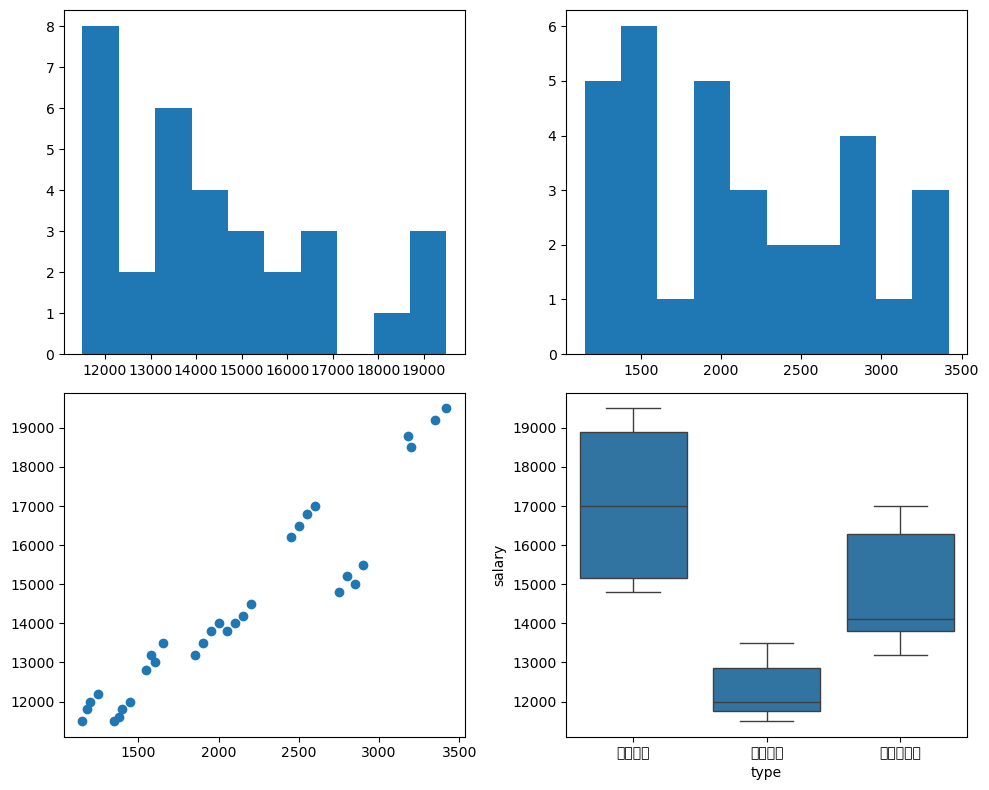

In [12]:
# 可视化
fig,axes=plt.subplots(2,2,figsize=(10,8))
axes[0,0].hist(df["salary"])
axes[0,1].hist(df["gdp"])
axes[1,0].scatter(df["gdp"],df["salary"])
sns.boxplot(df,x="type",y="salary",ax=axes[1,1])
plt.tight_layout()
plt.show()

D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 28909 (\N{CJK UNIFIED IDEOGRAPH-70ED}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21147 (\N{CJK UNIFIED IDEOGRAPH-529B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20851 (\N{CJK UNIFIED IDEOGRAPH-5173}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


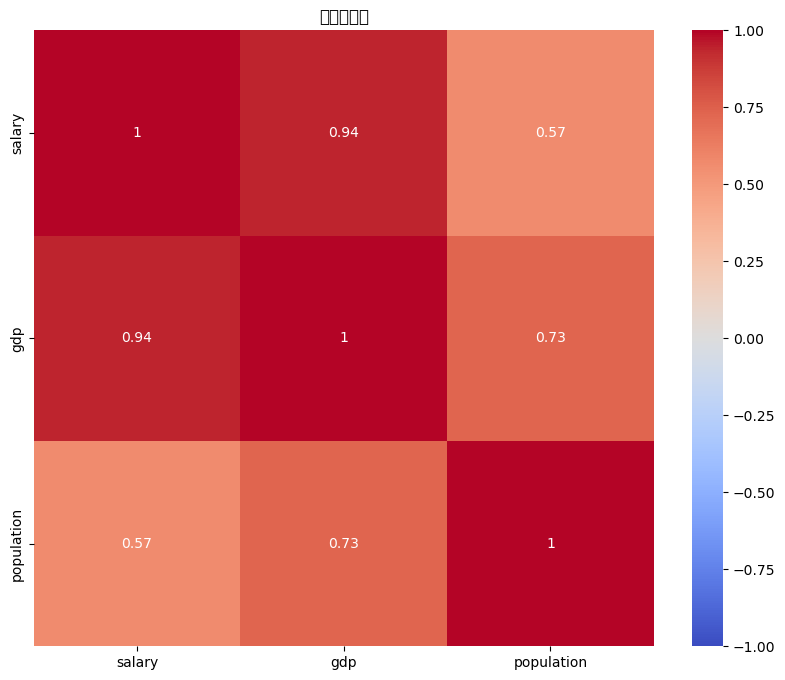

In [15]:
# 热力图
plt.figure(figsize=(10,8))
sns.heatmap(corr,annot=True,cmap="coolwarm",vmin=-1,vmax=1)
plt.title("热力相关图")
plt.show()